# EXP3: Real-data visualization

在 EBIV、Water 的 10–20 ms 事件窗口上估计并可视化速度场，六种方法共享完整的 10 ms 输入窗口；四种基线方法恢复为 21 个时间分箱，不再内部截取 3 ms。保存结果至 `output/EXP3/`。FWL、RSAT 评估见[附录实验](APPENDIX.ipynb)。


In [ ]:
import sys
import importlib
import time
from pathlib import Path

import torch
import numpy as np
from addict import Dict
import matplotlib.pyplot as plt


def find_project_root(start=None):
    start = Path.cwd() if start is None else Path(start).resolve()
    for path in [start, *start.parents]:
        if (path / "generator").is_dir() and (path / "methods").is_dir():
            return path
    raise RuntimeError("Cannot find project root. Please run this notebook inside the project directory.")


PROJECT_ROOT = find_project_root()
OUTPUT_DIR = PROJECT_ROOT / "output" / "EXP3"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# 数据加载：事件、光流
from generator.flow import FlowManager
from generator.images import config_events
from generator.loader import EventManager

# 可视化
from utils.visualizer import plot_events_3d, plot_event_time2d, save_voxel_grid_video, plot_flow_field
from methods.affinegs.cmax import ContrastMaximizationLoss
import methods.method as method_api
importlib.reload(method_api)
from methods.method import inr_vg, inr_est, of_vg, of_est, ilk_vg, ilk_est, affineGS, constGS, compute_flow_quantities
from methods.affinegs.gaussian_flow.config import GaussianFlowConfig
from methods.affinegs.gaussian_flow.training import run_gaussian_flow


In [ ]:
flow_index = 1
flow_names = ["ebiv", "water"]
time_window = (10.0, 20.0)  # 所有方法共享同一完整事件窗口。

cases = [
    Dict(source_type="real", path=str(PROJECT_ROOT / "data" / "real_old" / "ebiv_wallflow4_dense.h5")),
    # Dict(source_type="evk5", path=str(PROJECT_ROOT / "data" / "n1.hdf5"))
    Dict(source_type="evk5", path=str(PROJECT_ROOT / "data" / "water.hdf5"))
]

flow_cbar_cfgs = {
    0: dict(v_min=0.0, v_max=4.0, cbar_ticks=[0.0, 1.0, 2.0, 3.0, 4.0]),
    1: dict(v_min=0.0, v_max=2.0, cbar_ticks=[0.0, 0.5, 1.0, 1.5, 2.0]),
    # 1: dict(v_min=0.0, v_max=8.0, cbar_ticks=[0.0, 2, 4, 6, 8.0]),
}
flow_cbar_cfg = flow_cbar_cfgs[flow_index]
flow_font_size = 12
flow_cbar_label = "Magnitude [px/ms]"

event_loader = EventManager(**cases[flow_index])
evts, _ = event_loader.load()
print(evts[:, 2].max()-evts[:, 2].min(), evts[:, 2].min(), evts[:, 2].max())

evts1 = torch.tensor(evts[(evts[:, 2] > time_window[0]) & (evts[:, 2] < time_window[1])]).to(device)
print(evts1.shape)
plot_event_time2d(
    evts1,
    output_file=None,
    figsize=(5, 3),
    cbar_tick_size=flow_font_size,
    cbar_label_size=flow_font_size,
    image_rect=(0.02, 0.08, 0.84, 0.84),
    cbar_rect=(0.89, 0.08, 0.025, 0.84),
)
torch.cuda.empty_cache()

In [ ]:
start = time.time()
cfg = GaussianFlowConfig(H=720, W = 1280, init_n=500, w_div=100, verbose=False, tile_size=80, 
                         init_scale_h=50.0, init_scale_w=35.0,
                         cmax_sigma=0.6, cmax_kernel_size=5, lr_j=0.001, 
                         enable_jacobian=True, jacobian_mode="full", 
                         iterations=300, residual_block_size=40, prune_opacity_thresh=0.1,
                         log_scale_min=np.log(8), phase=[50, 200, 250])

results = run_gaussian_flow(events=evts1, cfg=cfg, flowgt=None)

end = time.time()     # 记录结束时间
print(f"运行时间: {end - start:.6f} 秒")
torch.cuda.empty_cache()

# Save the velocity field for the appendix evaluation.
gs_method_name = "AffineGS" if cfg.enable_jacobian else "ConstGS"
flow_result_dir = OUTPUT_DIR / "flow_fields"
flow_result_dir.mkdir(parents=True, exist_ok=True)
gs_flow_result_file = flow_result_dir / f"{gs_method_name}-{flow_names[flow_index]}.npz"
np.savez_compressed(
    gs_flow_result_file,
    flow=np.asarray(results.flow[:2], dtype=np.float32),
    method_name=gs_method_name,
    flow_name=flow_names[flow_index],
    H=cfg.H, W=cfg.W, event_count=len(evts1),
    time_window_ms=np.asarray(time_window),
    t_min=float(evts1[:, 2].min().item()),
    t_max=float(evts1[:, 2].max().item()),
)
print(f"saved flow: {gs_flow_result_file}")

运行时间: 1.442452 秒
saved flow: /media/newdisk/junjie/2dGS-representation/output/EXP3/flow_fields/AffineGS-water.npz


Figure saved to /media/newdisk/junjie/2dGS-representation/output/EXP3/AffineGS-water.pdf


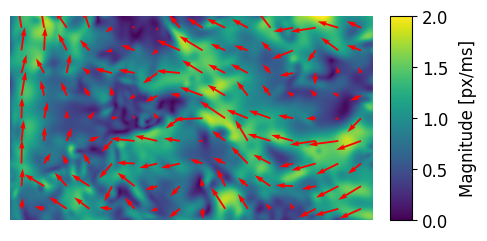

saved: /media/newdisk/junjie/2dGS-representation/output/EXP3/AffineGS-water.pdf


In [8]:
save_gs_result = True

gs_method_name = "AffineGS" if cfg.enable_jacobian else "ConstGS"
gs_output_file = str(OUTPUT_DIR / f"{gs_method_name}-{flow_names[flow_index]}.pdf") if save_gs_result else None

plot_flow_field(results.flow[0], results.flow[1], output_file=gs_output_file,
                v_min=flow_cbar_cfg["v_min"], v_max=flow_cbar_cfg["v_max"],
                cbar_ticks=flow_cbar_cfg["cbar_ticks"], 
                colorbar_flag=True, step=1, quiver_step=80, scale=None, 
                slFlag=False, figsize=(5, 3), cbar_tick_size=flow_font_size,
                cbar_label=flow_cbar_label, cbar_label_size=flow_font_size)
if save_gs_result:
    print(f"saved: {gs_output_file}")

In [ ]:
estimators = [ilk_vg, of_vg, inr_est, inr_vg]
method_names = ["ILK_VG", "OF_VG", "INR_EST", "INR_VG"]

# 0: ILK_VG, 1: OF_VG, 2: INR_EST, 3: INR_VG
method_index = 0
estimator_H = 720
estimator_W = 1280
estimator_num_bins = 21  # 恢复统一 3 ms 之前的 EXP3 时间分箱配置。

def compute_estimator_by_index(method_index, events, H=720, W=1280):
    if method_index < 0 or method_index >= len(estimators):
        raise IndexError(f"method_index must be in [0, {len(estimators) - 1}], got {method_index}")

    estimator = estimators[method_index]
    method_name = method_names[method_index]

    start = time.time()
    v_h, v_w, div, vor = estimator(
        events, H=H, W=W, event_window_ms=None, num_bins=estimator_num_bins
    )
    elapsed = time.time() - start
    torch.cuda.empty_cache()

    print(f"{method_name}: {elapsed:.4f} s")
    return Dict(
        method_index=method_index,
        method_name=method_name,
        v_h=v_h,
        v_w=v_w,
        div=div,
        vor=vor,
        elapsed=elapsed,
        H=H,
        W=W,
        temporal_num_bins=estimator_num_bins,
    )


method_result = compute_estimator_by_index(method_index, evts1, H=estimator_H, W=estimator_W)

# Save the velocity field for the appendix evaluation.
flow_result_dir = OUTPUT_DIR / "flow_fields"
flow_result_dir.mkdir(parents=True, exist_ok=True)
method_flow_result_file = flow_result_dir / f"{method_result.method_name}-{flow_names[flow_index]}.npz"
method_v_h = (method_result.v_h.detach().cpu().numpy()
              if torch.is_tensor(method_result.v_h) else np.asarray(method_result.v_h))
method_v_w = (method_result.v_w.detach().cpu().numpy()
              if torch.is_tensor(method_result.v_w) else np.asarray(method_result.v_w))
np.savez_compressed(
    method_flow_result_file,
    flow=np.stack((method_v_h, method_v_w)).astype(np.float32, copy=False),
    method_name=method_result.method_name,
    flow_name=flow_names[flow_index],
    H=method_result.H, W=method_result.W, event_count=len(evts1),
    temporal_num_bins=method_result.temporal_num_bins,
    time_window_ms=np.asarray(time_window),
    t_min=float(evts1[:, 2].min().item()),
    t_max=float(evts1[:, 2].max().item()),
)
print(f"saved flow: {method_flow_result_file}")

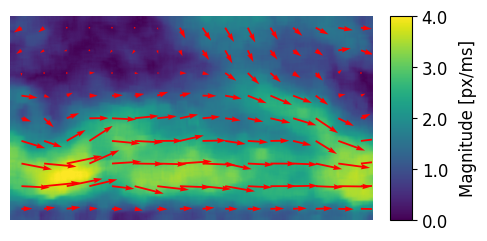

In [6]:
save_method_result = False

method_output_file = str(OUTPUT_DIR / f"{method_result.method_name}-{flow_names[flow_index]}.pdf") if save_method_result else None

plot_flow_field(
    method_result.v_h, method_result.v_w, None, None,
    output_file=method_output_file,
    magFlag=True, slFlag=False, colorbar_flag=True,
    step=1, quiver_step=80,
    v_min=flow_cbar_cfg["v_min"], v_max=flow_cbar_cfg["v_max"],
    scale=None, figsize=(5, 3),
    cbar_ticks=flow_cbar_cfg["cbar_ticks"], cbar_tick_size=flow_font_size,
    cbar_label=flow_cbar_label, cbar_label_size=flow_font_size,
)
if save_method_result:
    print(f"saved: {method_output_file}")